# Lab02 — Product Sales Prediction

Notebook đọc lại một lần thực nghiệm đã hoàn thành. Các bảng và mô hình lấy từ cùng run_id, giúp trình bày nhất quán mà không ghi đè kết quả tham chiếu. Chạy python -m Lab02.src.pipeline trước nếu chưa có kết quả.

## 1. Mục tiêu và thiết lập

Dự đoán số lượng bán dương cho một sản phẩm/ngày. Bốn thuật toán tự cài gồm Ridge, Decision Tree, Random Forest và Gradient Boosting. Tiêu chí chọn là selection_rmse trên các giai đoạn quá khứ và validation, test dành cho đánh giá cuối.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml,joblib

repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p / "Lab02/src/config.yaml").is_file())
if str(repo) not in sys.path:
    sys.path.insert(0,str(repo))
from Lab02.src.preprocessing import LAB,FEATURES,build_preprocessor
from Lab02.src.evaluate import metrics
from Lab02.src.train import train_model

published=json.loads((LAB / "models/selection.json").read_text())
run=LAB / "results/runs" / published["run_id"]
manifest=json.loads((run / "run.json").read_text())
if manifest["status"]!="success":
    raise RuntimeError("Select a completed run.")
config=yaml.safe_load((run / "config.yaml").read_text())
selected=json.loads((run / "tuning/selection.json").read_text())
print("Reference run:",run.name)
print("Winner selected before test:",published["winner"])
print(json.dumps(config,ensure_ascii=False,indent=2))


Reference run: 2026-11-18_21-14-12
Winner selected before test: random_forest
{
  "data": {
    "encoding": "cp1252",
    "path": "data/raw/E-Commerc.csv",
    "top_products": 20
  },
  "experiment": {
    "forecast": "rolling_one_day_ahead",
    "product_scope": "fixed_top_products_selected_from_full_train",
    "selection": "mean_rmse_three_expanding_folds_and_validation"
  },
  "models": {
    "decision_tree": [
      {
        "feature_set": "basic",
        "max_depth": 5,
        "min_samples_leaf": 10
      },
      {
        "feature_set": "trend",
        "max_depth": 5,
        "min_samples_leaf": 10
      },
      {
        "feature_set": "basic",
        "max_depth": 10,
        "min_samples_leaf": 20
      },
      {
        "feature_set": "trend",
        "max_depth": 10,
        "min_samples_leaf": 20
      },
      {
        "feature_set": "trend",
        "max_depth": 4,
        "min_samples_leaf": 20
      },
      {
        "feature_set": "robust",
        "max_depth

**Kết quả và nhận xét.** Cấu hình trên là bản snapshot của lần chạy, có thể khác YAML đang chỉnh sửa trong src. Toàn bộ ô sau dùng cùng thư mục run.

## 2. Dữ liệu và EDA

Nguồn là giao dịch E-Commerc.csv. Tập mô hình tổng hợp theo sản phẩm/ngày, loại giao dịch hủy, trả hàng và giá không dương. Ngày không có bản ghi được giả định bán 0, chưa phân biệt hết hàng hay ngày nghỉ.

Source rows: 541909
InvoiceNo StockCode                         Description  Quantity    InvoiceDate  UnitPrice  CustomerID        Country
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 12/1/2010 8:26       2.55     17850.0 United Kingdom
   536365     71053                 WHITE METAL LANTERN         6 12/1/2010 8:26       3.39     17850.0 United Kingdom
   536365    84406B      CREAM CUPID HEARTS COAT HANGER         8 12/1/2010 8:26       2.75     17850.0 United Kingdom
   536365    84029G KNITTED UNION FLAG HOT WATER BOTTLE         6 12/1/2010 8:26       3.39     17850.0 United Kingdom
   536365    84029E      RED WOOLLY HOTTIE WHITE HEART.         6 12/1/2010 8:26       3.39     17850.0 United Kingdom
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
{
  "raw_rows": 541909,
  "deduplicated_rows": 536641,
  "duplicate_rows_removed": 5268,
 

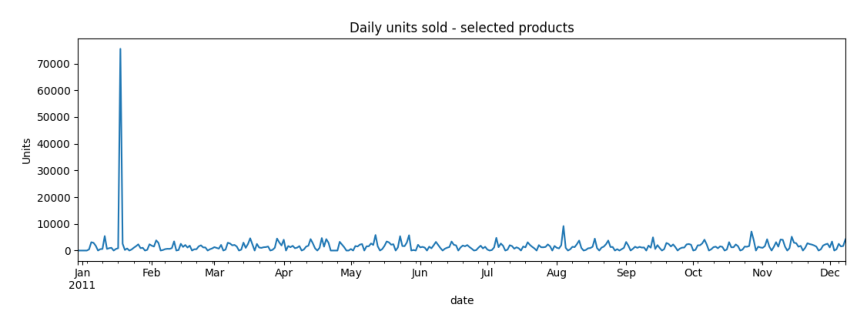

In [2]:
raw=pd.read_csv(LAB / config["data"]["path"],encoding=config["data"]["encoding"],
                dtype={"InvoiceNo":str,"StockCode":str})
print("Source rows:",len(raw))
print(raw.head().to_string(index=False))
print(raw.isna().sum().to_string())
summary=json.loads((run / "preprocessing/summary.json").read_text())
print(json.dumps(summary,ensure_ascii=False,indent=2))
plt.figure(figsize=(12,4))
plt.imshow(plt.imread(run / "figures/daily_sales.png"))
plt.axis("off")
plt.show()


**Nhận xét.** Giữ số lượng lớn hợp lệ có thể làm RMSE nhạy với các ngày bán buôn. CustomerID thiếu không tham gia đặc trưng hiện tại. Phạm vi chỉ gồm các sản phẩm đã chọn từ train.

## 3. Chia thời gian và đặc trưng

Train, validation và test nối tiếp theo ngày. Lag và rolling chỉ dùng ngày trước. Tiền xử lý số và từ vựng sản phẩm chỉ được fit trên phần train tương ứng. Ví dụ dưới đây fit bộ xử lý riêng để minh họa, không thay bộ xử lý đã lưu.

In [3]:
frames={name:pd.read_csv(run / "preprocessing" / f"{name}.csv",dtype={"StockCode":str},float_precision="round_trip")
        for name in ["train","validation","test"]}
train,validation,test=(frames[name] for name in ["train","validation","test"])
assert train.date.max()<validation.date.min()
assert validation.date.max()<test.date.min()
overview=pd.DataFrame([{"split":name,"rows":len(frame),"start":frame.date.min(),"end":frame.date.max()}
                       for name,frame in frames.items()])
print(overview.to_string(index=False))
processor=build_preprocessor("basic")
X=processor.fit_transform(train[FEATURES])
V=processor.transform(validation[FEATURES])
print("Training shape:",X.shape,"| Validation shape:",V.shape)
print("Feature columns:",FEATURES)


     split  rows      start        end
     train  3900 2010-12-30 2011-07-12
validation  1480 2011-07-13 2011-09-24
      test  1500 2011-09-25 2011-12-08
Training shape: (3900, 27) | Validation shape: (1480, 27)
Feature columns: ['StockCode', 'lag_1', 'lag_7', 'mean_7', 'mean_28', 'month', 'weekday', 'day_of_year', 'median_7', 'median_28', 'std_7', 'std_28', 'zero_days_28', 'same_weekday_mean_4']


**Nhận xét.** Tỷ lệ sau tạo lịch sử không đúng tuyệt đối 60/20/20 vì bỏ 28 ngày đầu chưa đủ dữ liệu. Đánh giá rolling one-step sử dụng số bán thực tế đến hết ngày trước, chưa tương đương dự báo nhiều ngày cùng lúc.

## 4. Baseline trên validation

So sánh dự đoán trung bình chung, cùng ngày tuần trước và trung bình theo sản phẩm. Mọi baseline dưới đây chỉ học từ train rồi chấm validation.

In [4]:
baseline_predictions={
    "mean":np.repeat(train.sales.mean(),len(validation)),
    "last_week":validation.lag_7.to_numpy(),
    "rolling_7":validation.mean_7.to_numpy(),
    "rolling_28":validation.mean_28.to_numpy(),
    "weekday_4":validation.same_weekday_mean_4.to_numpy(),
    "product_mean":validation.StockCode.map(train.groupby("StockCode").sales.mean()).to_numpy(),
}
baseline_validation=pd.DataFrame([{"baseline":name,**metrics(validation.sales,prediction)}
                                 for name,prediction in baseline_predictions.items()])
print(baseline_validation.to_string(index=False))


    baseline       mae          mse       rmse        r2
        mean 85.955759 26389.334284 162.447943 -0.013244
   last_week 84.765541 43176.364189 207.789230 -0.657799
   rolling_7 79.429730 27995.923662 167.319824 -0.074931
  rolling_28 74.130261 26151.393345 161.713924 -0.004108
   weekday_4 72.982770 29868.769257 172.825835 -0.146841
product_mean 90.961140 32444.859855 180.124568 -0.245752


**Nhận xét.** Baseline giúp kiểm tra mức cải thiện thực tế. Cấu hình phức tạp cần được đối chiếu trên cùng giai đoạn, không chỉ dựa vào điểm của một mô hình riêng.

## 5. Tuning và walk-forward

Mỗi ứng viên được huấn luyện trên ba cửa sổ mở rộng trong train và trên toàn bộ train để chấm validation cuối. selection_rmse lấy trung bình RMSE bốn giai đoạn. tune() dùng train_model() trong src/train.py, fit lại bộ tiền xử lý cho từng lượt.

In [5]:
trials=pd.read_csv(run / "tuning/validation_metrics.csv")
folds=pd.read_csv(run / "tuning/walk_forward_metrics.csv")
print(trials.to_string(index=False))
print(folds.head(12).to_string(index=False))
assert (pd.to_datetime(folds.train_end)<pd.to_datetime(folds.validation_start)).all()


            model                                                                             parameters       mae          mse       rmse        r2  selection_rmse  walk_forward_rmse_std
linear_regression     {'alpha': 1.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'basic'} 83.217995 34860.531221 186.709751 -0.338504      372.186845             243.201634
linear_regression     {'alpha': 1.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'trend'} 83.218106 34860.609913 186.709962 -0.338507      372.219040             243.258413
linear_regression    {'alpha': 10.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'basic'} 82.235668 34166.562707 184.841994 -0.311859      316.467945             154.247946
linear_regression    {'alpha': 10.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'trend'} 82.236825 34167.297754 184.843982 -0.311887      316.619362             154.503034
linear_regression    {'alpha': 1.0, 'learning_rate': 0.1, 'n

**Nhận xét.** So sánh basic và trend là so sánh các đặc trưng lịch sử. Danh sách top sản phẩm được chọn trước các fold từ giai đoạn train tổng, nên đây là kiểm tra trên danh mục sản phẩm đã chốt, chưa mô phỏng lại việc chọn danh mục ở mỗi mốc quá khứ.

## 6. Lựa chọn cuối

Mỗi họ thuật toán giữ cấu hình selection_rmse thấp nhất. Mô hình demo được chọn từ cùng tiêu chí trước khi chấm test. Các cấu hình cuối được fit lại trên train cộng validation.

In [6]:
print(json.dumps(selected,ensure_ascii=False,indent=2))
best=trials.sort_values("selection_rmse",kind="stable").drop_duplicates("model")
print(best[["model","parameters","selection_rmse"]].to_string(index=False))
print("Published winner:",published["winner"])


{
  "linear_regression": {
    "alpha": 100.0,
    "learning_rate": 0.1,
    "n_iterations": 3000,
    "feature_set": "robust"
  },
  "decision_tree": {
    "max_depth": 5,
    "min_samples_leaf": 10,
    "feature_set": "trend"
  },
  "random_forest": {
    "n_estimators": 60,
    "max_depth": 10,
    "min_samples_leaf": 5,
    "feature_set": "trend"
  },
  "gradient_boosting": {
    "n_estimators": 60,
    "max_depth": 2,
    "learning_rate": 0.05,
    "feature_set": "trend"
  }
}
            model                                                                            parameters  selection_rmse
    random_forest  {'n_estimators': 60, 'max_depth': 10, 'min_samples_leaf': 5, 'feature_set': 'trend'}      217.143464
linear_regression {'alpha': 100.0, 'learning_rate': 0.1, 'n_iterations': 3000, 'feature_set': 'robust'}      232.758556
    decision_tree                      {'max_depth': 5, 'min_samples_leaf': 10, 'feature_set': 'trend'}      300.322349
gradient_boosting   {'n_estimator

**Nhận xét.** Chọn trước bằng dữ liệu phát triển giúp giữ đúng vai trò test. Ngưỡng dưới 0 được cắt về 0 khi xuất số lượng dự đoán.

## 7. Đánh giá test, dự đoán và phần dư

Nạp mô hình của đúng run, tính lại chỉ số bằng hàm tự cài và đối chiếu metrics.csv đã lưu.

                model  fit_seconds       mae          mse       rmse        r2
    linear_regression     0.267499 76.352911 45557.535253 213.442112  0.108652
        decision_tree     0.108148 77.581830 47927.756897 218.924089  0.062278
        random_forest     8.341682 78.474516 46317.075891 215.214023  0.093792
    gradient_boosting     1.770982 87.948191 50810.150397 225.411070  0.005883
        mean_baseline     0.000000 95.700132 51121.721506 226.101131 -0.000213
   last_week_baseline     0.000000 96.256667 77078.894000 277.630859 -0.508073
   rolling_7_baseline     0.000000 89.009048 50427.508367 224.560701  0.013370
  rolling_28_baseline     0.000000 82.179190 46341.112577 215.269860  0.093321
   weekday_4_baseline     0.000000 85.301667 52048.347500 228.141069 -0.018342
product_mean_baseline     0.000000 95.478942 52808.516754 229.801037 -0.033215
Recomputed winner metrics: {'mae': 78.47451579289151, 'mse': 46317.07589088706, 'rmse': 215.2140234531362, 'r2': 0.0937917580500887

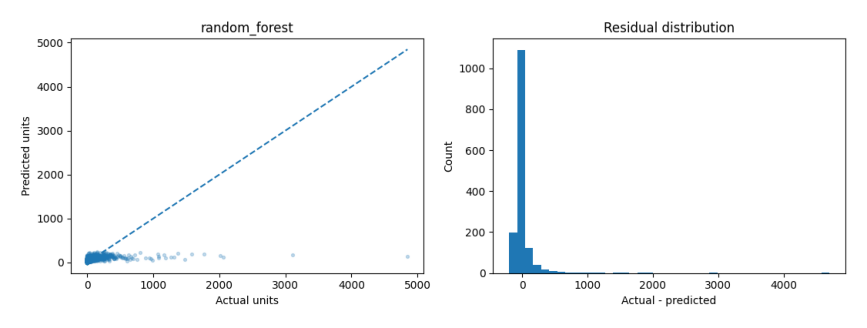

In [7]:
results=pd.read_csv(run / "evaluation/metrics.csv")
print(results.to_string(index=False))
winner=published["winner"]
model=joblib.load(run / "models" / f"{winner}.joblib")
predicted=np.maximum(0,model.predict(test[FEATURES]))
recomputed=metrics(test.sales,predicted)
saved=results.loc[results.model==winner].iloc[0]
for name,value in recomputed.items():
    assert np.isclose(value,saved[name])
print("Recomputed winner metrics:",recomputed)
plt.figure(figsize=(12,4))
plt.imshow(plt.imread(run / "figures" / f"{winner}.png"))
plt.axis("off")
plt.show()
error_files=sorted((run / "evaluation").glob(f"{winner}*largest_errors.csv"))
if error_files:
    print(pd.read_csv(error_files[0]).head(10).to_string(index=False))


**Nhận xét.** Phần dư dương là dự báo thiếu. R² thấp cho biết biến động doanh số còn khó giải thích bằng bộ đặc trưng hiện tại. Đọc thêm bảng lỗi theo sản phẩm và thứ để hiểu nơi mô hình thất bại.

## 8. Kết luận và đầu ra

Notebook đọc lại kết quả. Muốn thực nghiệm cấu hình mới, sửa YAML và chạy pipeline để tạo thư mục riêng. Pipeline lưu model, preprocessing, tuning, evaluation, figures, config và lịch sử cùng run_id.

In [8]:
baseline_rmse=float(results.loc[results.model=="mean_baseline","rmse"].iloc[0])
winner_rmse=float(saved["rmse"])
print("Model selected on development:",winner)
print("Test RMSE improvement vs mean baseline (%):",100*(baseline_rmse-winner_rmse)/baseline_rmse)
print("Test R2:",float(saved["r2"]))
print("Run:",run)
print("This notebook writes no experimental artifacts into the reference run.")


Model selected on development: random_forest
Test RMSE improvement vs mean baseline (%): 4.815149592383298
Test R2: 0.0937917580500887
Run: E:\ML_Nhóm6\Lab02\results\runs\2026-11-18_21-14-12
This notebook writes no experimental artifacts into the reference run.


**Kết luận.** Tách đánh giá chất lượng thuật toán khỏi chất lượng quy trình. Báo cáo cần trình bày phạm vi 20 sản phẩm, giả định ngày bán 0 và việc cần lịch sử 28 ngày trước mỗi dự đoán. Khả năng triển khai thực tế cần thêm dữ liệu và kiểm tra nguồn khác.